# AI/ML Task 2: Enhanced House Price Prediction & Model Comparison

**Objective:** Build a professional-style Machine Learning workflow that prepares data correctly, trains multiple regression models, compares them with measurable metrics, and selects the best model with justification.

**Dataset:** California Housing Dataset (scikit-learn) | **Target:** Median House Value (in units of $100,000)

**Tools:** Python, Jupyter Notebook, pandas, NumPy, scikit-learn, matplotlib / seaborn

## Step 1: Import Required Libraries
These libraries handle data manipulation, model training, evaluation, and visualization.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

sns.set_style("whitegrid")

## Step 2: Load the Dataset
At this stage, review column names, data types, and the target variable.

In [2]:
data = fetch_california_housing(as_frame=True)
df = pd.concat([data.data, data.target.rename("HousePrice")], axis=1)

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isnull().sum())
df.info()

Shape: (20640, 9)

Missing values per column:
 MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
HousePrice    0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   HousePrice  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096650,0.474503,0.333333,1.005630,1.048820,1.100000,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
HousePrice,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


### Quick Exploratory Look (optional insight)
How strongly is each feature related to the house price?

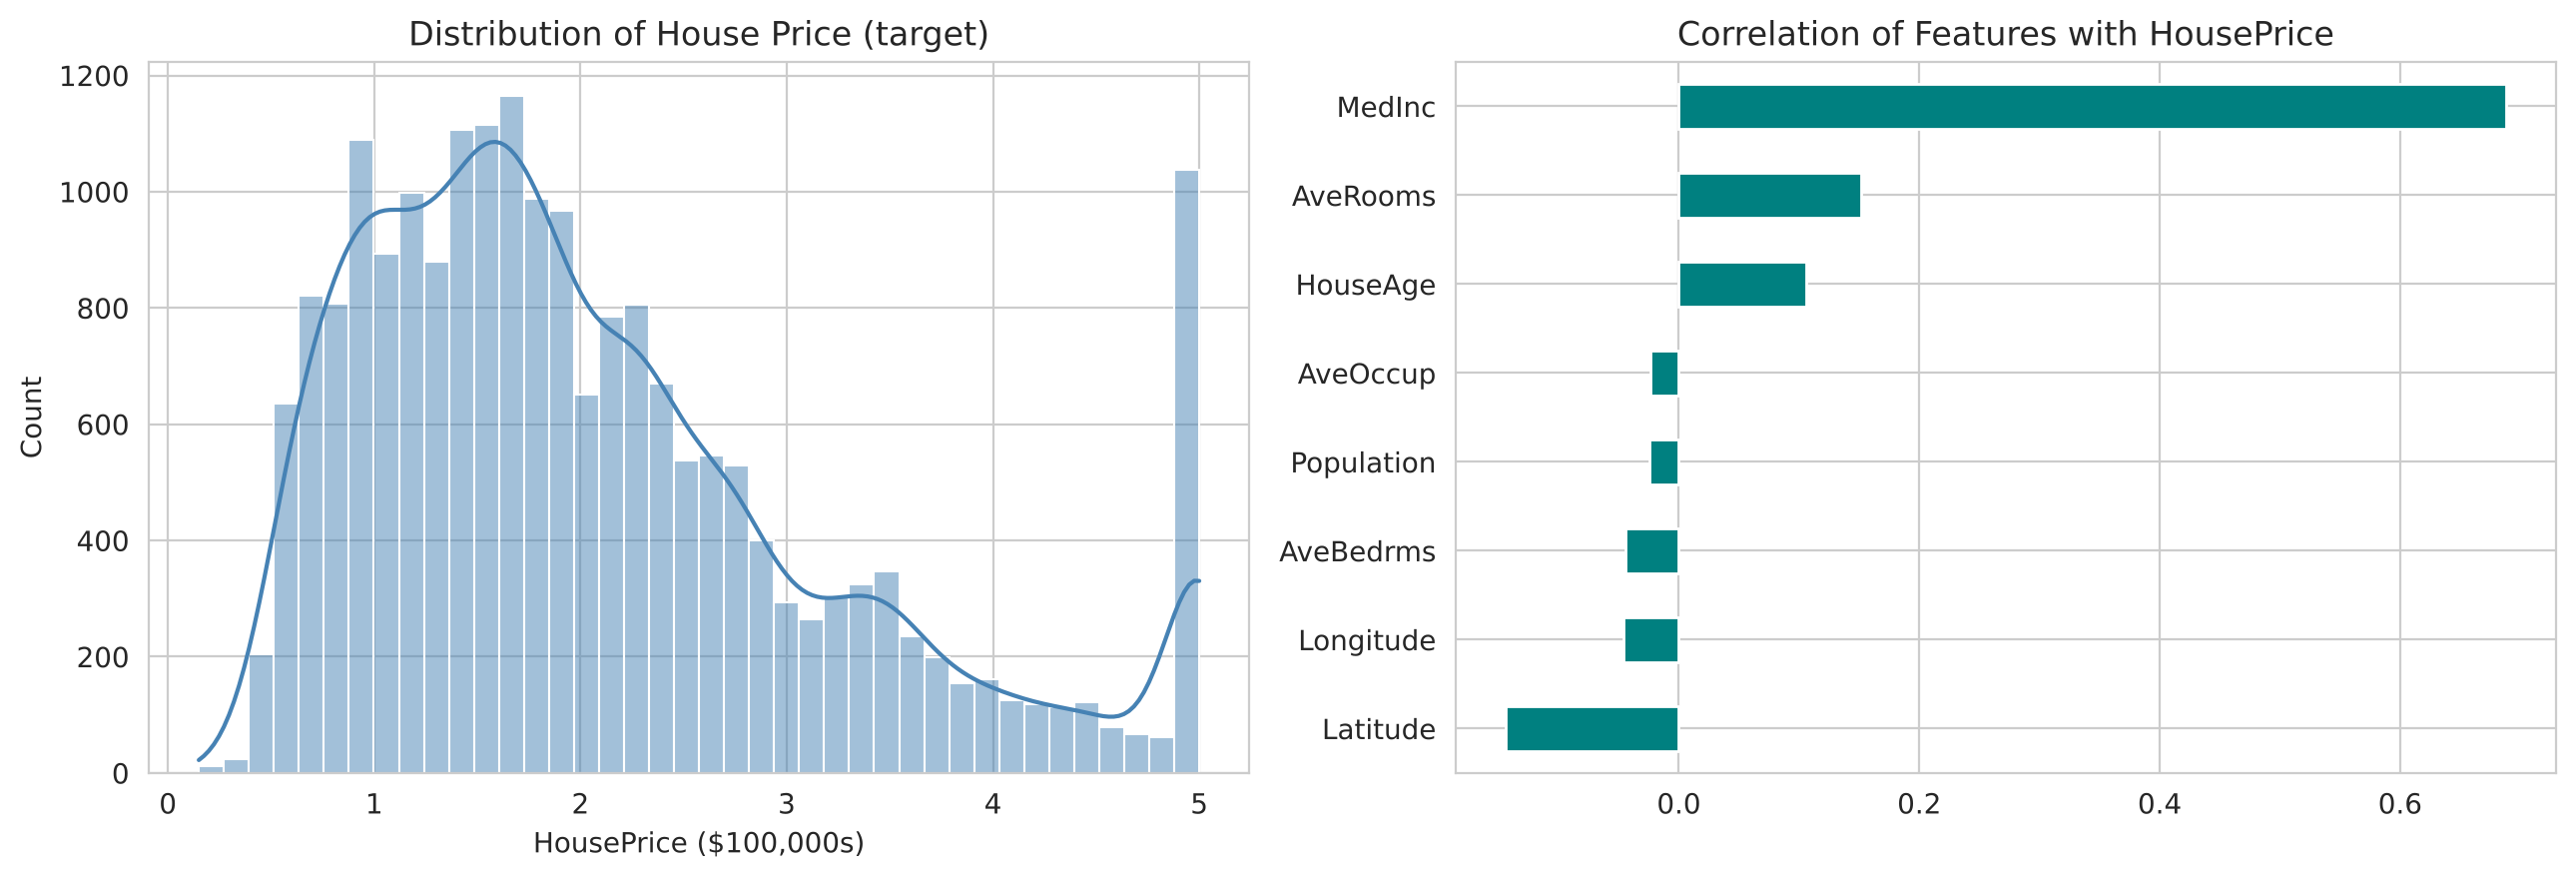

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["HousePrice"], bins=40, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of House Price (target)")
ax[0].set_xlabel("HousePrice ($100,000s)")

corr = df.corr()["HousePrice"].drop("HousePrice").sort_values()
corr.plot(kind="barh", ax=ax[1], color="teal")
ax[1].set_title("Correlation of Features with HousePrice")

plt.tight_layout()
plt.show()

## Step 3: Separate Features and Target Variable
Machine Learning models require input features (`X`) and the output variable (`y`) to be handled separately.

In [6]:
X = df.drop("HousePrice", axis=1)
y = df["HousePrice"]

print("Features:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X shape: (20640, 8) | y shape: (20640,)


## Step 4: Feature Scaling (Critical Step)
Features exist on very different numeric ranges (e.g. `Population` is in the thousands, `MedInc` is single digits).

Without scaling, some features dominate others and model performance becomes unstable.

In [7]:
print("Before scaling (feature ranges):")
display(X.describe().loc[["min", "max"]].T)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("After scaling - mean ~ 0, std ~ 1:")
display(pd.DataFrame(X_scaled, columns=X.columns).describe().loc[["mean", "std"]].T.round(3))

Before scaling (feature ranges):


,min,max
MedInc,0.499900,15.000100
HouseAge,1.000000,52.000000
AveRooms,0.846154,141.909091
AveBedrms,0.333333,34.066667
Population,3.000000,35682.000000
AveOccup,0.692308,1243.333333
Latitude,32.540000,41.950000
Longitude,-124.350000,-114.310000


After scaling - mean ~ 0, std ~ 1:


,mean,std
MedInc,0.0,1.0
HouseAge,0.0,1.0
AveRooms,0.0,1.0
AveBedrms,0.0,1.0
Population,-0.0,1.0
AveOccup,0.0,1.0
Latitude,0.0,1.0
Longitude,-0.0,1.0


After scaling, all features share a common scale, improving learning stability and performance.

## Step 5: Train-Test Split
This ensures the model is evaluated on unseen data rather than memorized values (80% train / 20% test).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 16512
Testing samples : 4128


## Step 6: Train Multiple Models
Instead of relying on a single algorithm, we train and evaluate multiple models.

**Model rationale:**
- **Linear Regression** serves as a baseline
- **Ridge Regression** helps reduce overfitting (L2 regularization)
- **Decision Tree** captures non-linear relationships

In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Linear Regression
Trained: Ridge Regression
Trained: Decision Tree


## Step 7: Model Evaluation and Comparison
- **Lower RMSE** indicates better prediction accuracy
- **Higher R²** indicates better explanatory power

Train R² is also recorded: a large gap between Train R² and Test R² is a sign of **overfitting** (introduction).

> Note: newer scikit-learn versions removed the `squared=False` argument, so RMSE is computed as `np.sqrt(mean_squared_error(...))`.

In [10]:
results = {}

for name, model in models.items():
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    r2 = r2_score(y_test, test_pred)

    results[name] = {
        "RMSE": rmse,
        "R2 Score": r2,
        "Train R2": r2_score(y_train, train_pred),
        "Overfit Gap (Train-Test R2)": r2_score(y_train, train_pred) - r2,
    }

results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df = results_df.round(4)
results_df

,RMSE,R2 Score,Train R2,Overfit Gap (Train-Test R2)
Decision Tree,0.7242,0.5997,0.6377,0.0379
Ridge Regression,0.7476,0.5735,0.6126,0.0390
Linear Regression,0.7476,0.5735,0.6126,0.0391


In [11]:
# Save the comparison table (Deliverable 2)
results_df.to_csv("model_performance_comparison.csv")

best_name = results_df["RMSE"].idxmin()
print("Best model (lowest RMSE):", best_name)

Best model (lowest RMSE): Decision Tree


### Visual Comparison of Models

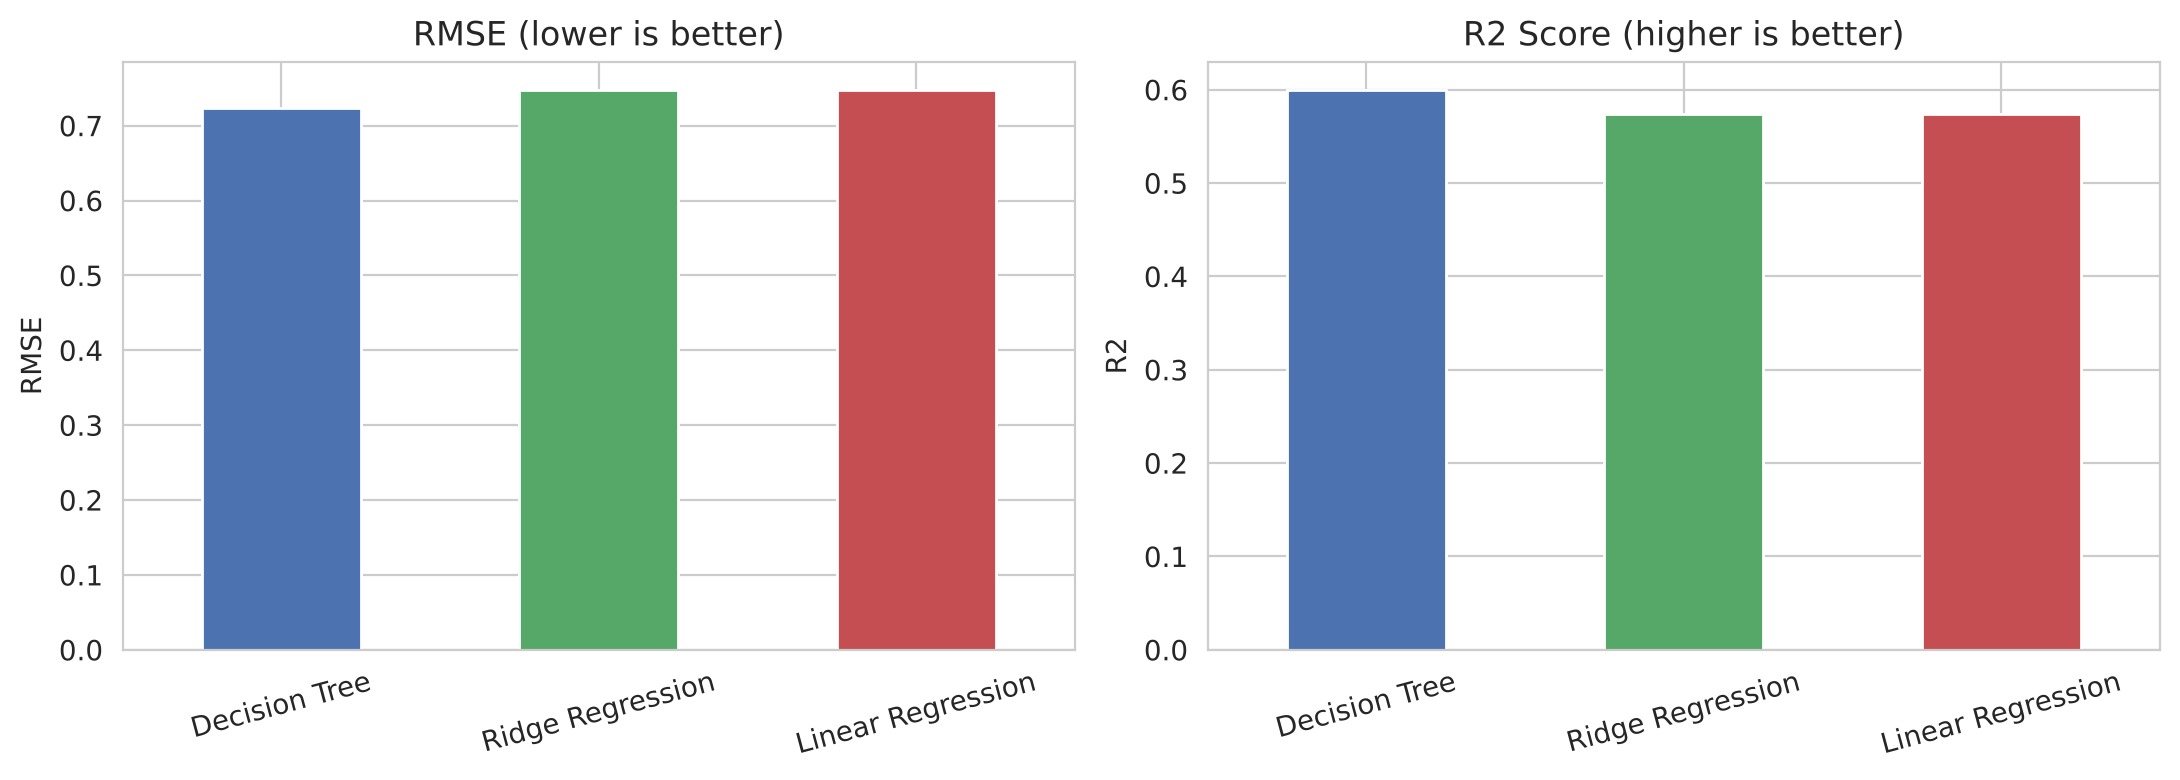

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#4C72B0", "#55A868", "#C44E52"]

results_df["RMSE"].plot(kind="bar", ax=ax[0], color=colors, rot=15)
ax[0].set_title("RMSE (lower is better)")
ax[0].set_ylabel("RMSE")

results_df["R2 Score"].plot(kind="bar", ax=ax[1], color=colors, rot=15)
ax[1].set_title("R2 Score (higher is better)")
ax[1].set_ylabel("R2")

plt.tight_layout()
plt.savefig("model_comparison_chart.png", dpi=150)
plt.show()

### Cross-Validation Check (reliability of the ranking)
A single train-test split can be lucky or unlucky. 5-fold cross-validation (with scaling done *inside* each fold to avoid data leakage) confirms whether the ranking is stable.

In [13]:
cv_rows = {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipe, X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
    cv_rows[name] = {"CV Mean R2": scores.mean(), "CV Std R2": scores.std()}

cv_df = pd.DataFrame(cv_rows).T.round(4)
cv_df

,CV Mean R2,CV Std R2
Linear Regression,0.6008,0.0176
Ridge Regression,0.6008,0.0176
Decision Tree,0.6111,0.0113


## Step 8: Visual Performance Validation
The best-performing model (selected from the results table) is plotted. A closer alignment of points to the red reference line indicates better predictive performance.

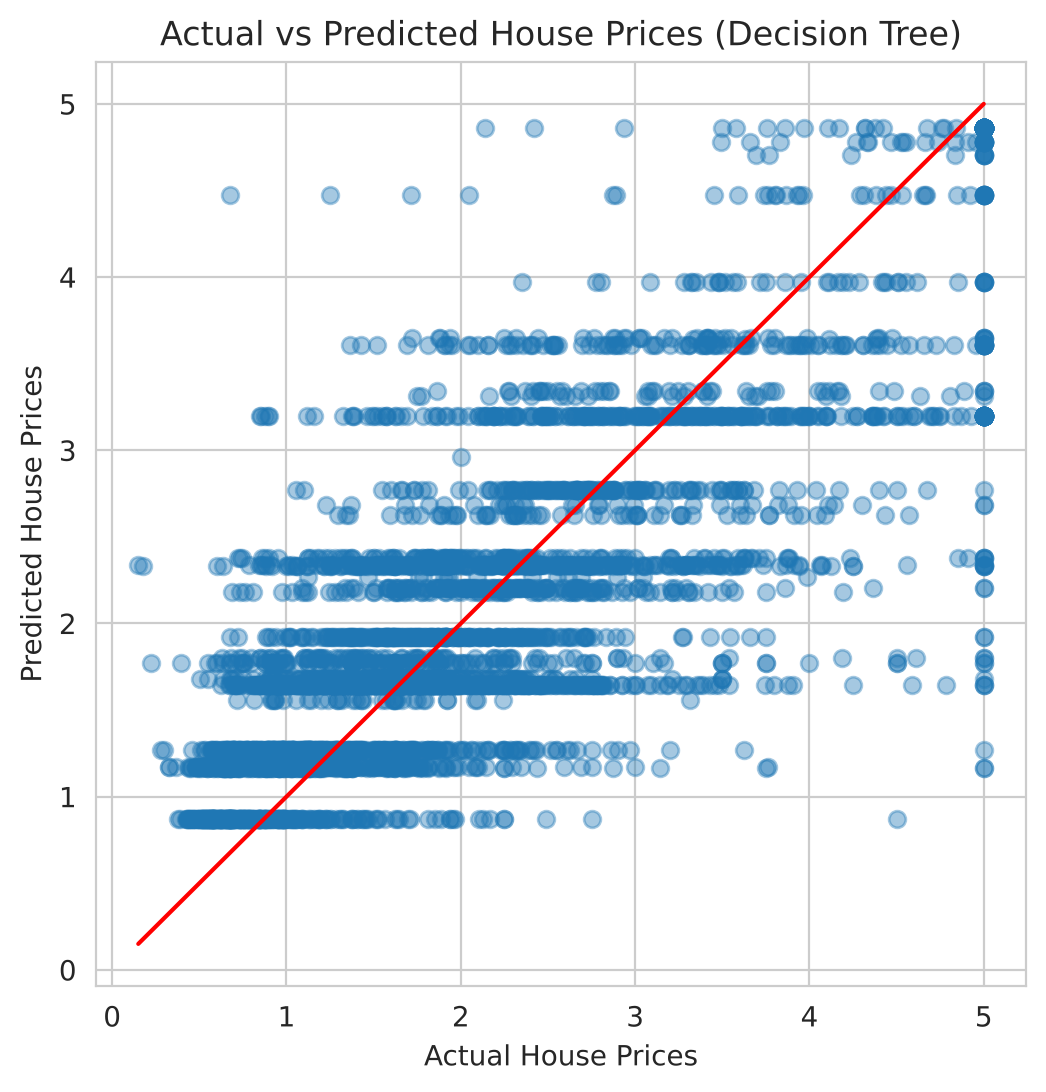

In [14]:
best_model = models[best_name]
y_pred = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title(f"Actual vs Predicted House Prices ({best_name})")
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red")
plt.savefig("actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

### Optional: Residual Analysis

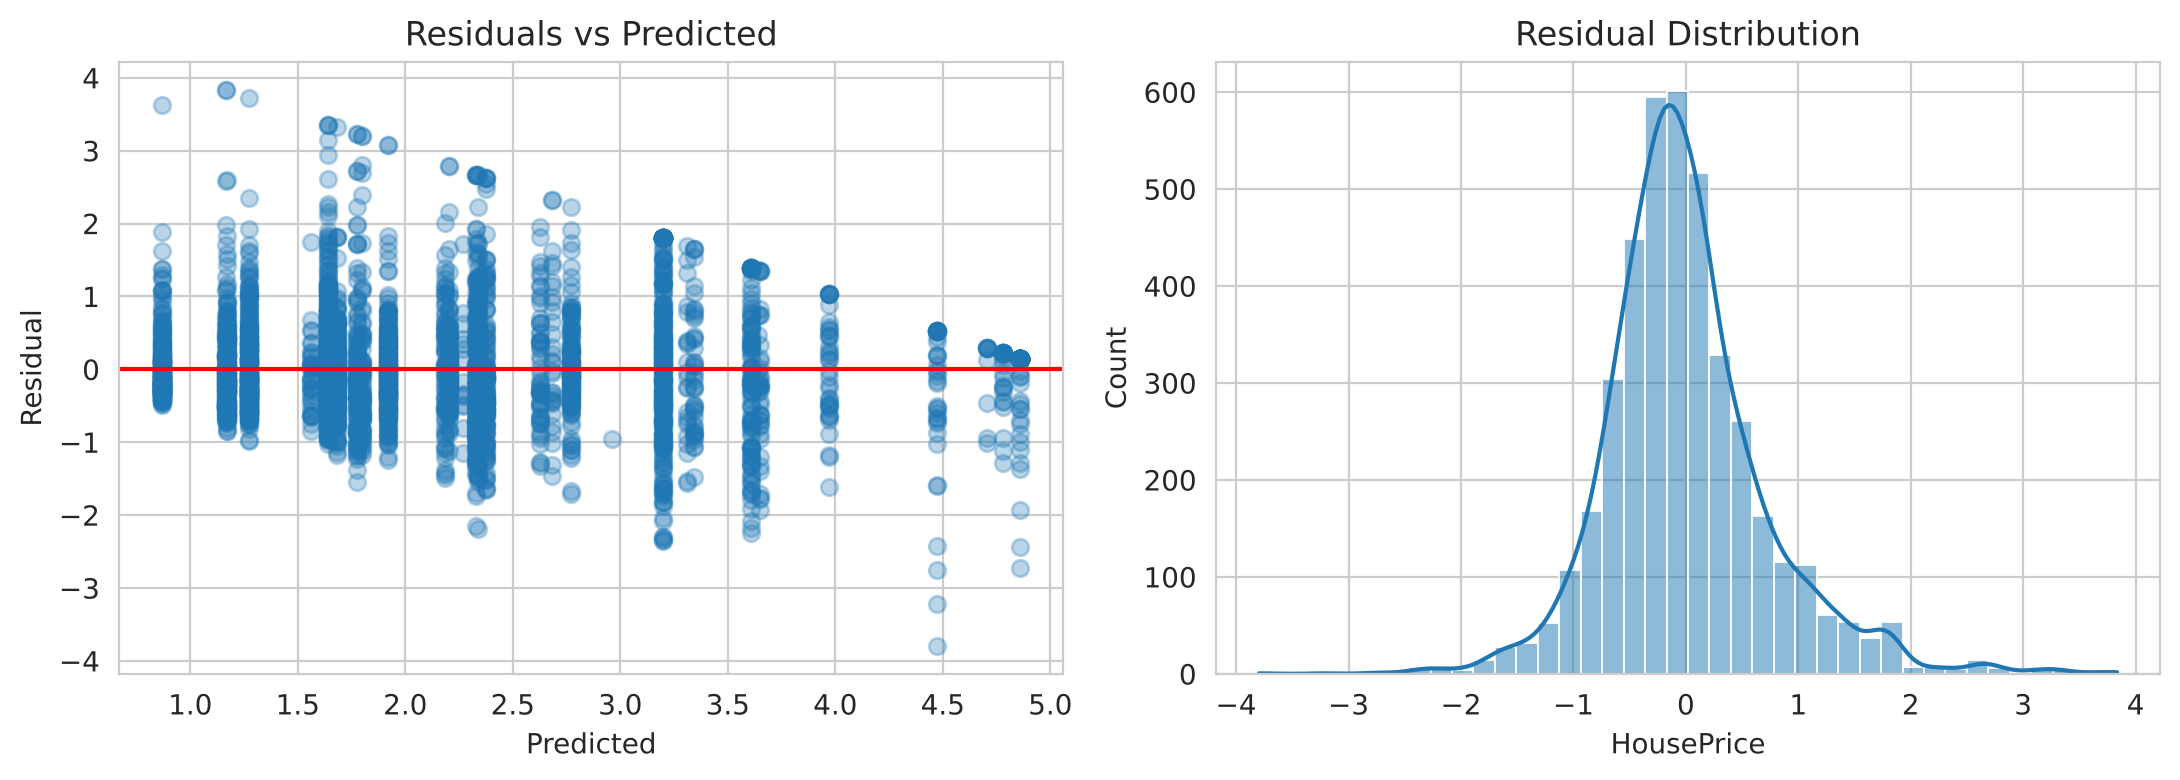

In [15]:
residuals = y_test - y_pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_pred, residuals, alpha=0.3)
ax[0].axhline(0, color="red")
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Residual"); ax[0].set_title("Residuals vs Predicted")
sns.histplot(residuals, bins=40, kde=True, ax=ax[1])
ax[1].set_title("Residual Distribution")
plt.tight_layout()
plt.show()

### Optional: Save the Best Model (joblib)

In [16]:
import joblib

joblib.dump({"model": best_model, "scaler": scaler, "features": list(X.columns)},
            "best_house_price_model.joblib")
print("Saved: best_house_price_model.joblib")

Saved: best_house_price_model.joblib


## Final Model Selection & Justification

In [17]:
b = results_df.loc[best_name]
print(f"Selected model : {best_name}")
print(f"Test RMSE      : {b['RMSE']:.4f}  (x $100,000)")
print(f"Test R2        : {b['R2 Score']:.4f}")
print(f"Train-Test gap : {b['Overfit Gap (Train-Test R2)']:.4f}")
print()
print("Ranking by RMSE:")
for i, (n, r) in enumerate(results_df.iterrows(), 1):
    print(f"  {i}. {n:<18} RMSE={r['RMSE']:.4f}  R2={r['R2 Score']:.4f}")

Selected model : Decision Tree
Test RMSE      : 0.7242  (x $100,000)
Test R2        : 0.5997
Train-Test gap : 0.0379

Ranking by RMSE:
  1. Decision Tree      RMSE=0.7242  R2=0.5997
  2. Ridge Regression   RMSE=0.7476  R2=0.5735
  3. Linear Regression  RMSE=0.7476  R2=0.5735


## Deliverable 3: 1-2 Page PDF Report
The next cell builds the PDF (methodology, results, conclusions) automatically from the results above, so the report always matches this notebook's output.

In [18]:
# Deliverable 3: auto-generate the 1-2 page PDF report from THIS notebook's results
# (if reportlab is missing, run:  pip install reportlab)
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image

ss = getSampleStyleSheet()
body = ParagraphStyle("b", parent=ss["Normal"], fontSize=9.5, leading=13)
h2 = ParagraphStyle("h2", parent=ss["Heading2"], fontSize=12, spaceBefore=8, spaceAfter=3, textColor=colors.HexColor("#1F3A5F"))
title = ParagraphStyle("t", parent=ss["Title"], fontSize=17, spaceAfter=2)
sub = ParagraphStyle("s", parent=body, alignment=1, textColor=colors.grey)

b = results_df.loc[best_name]
cv_best = cv_df["CV Mean R2"].idxmax()
why = {
    "Decision Tree": "it can capture non-linear relationships between features (such as income and location) and house prices, and limiting max_depth to 5 keeps it from memorising the training data",
    "Ridge Regression": "its L2 regularisation keeps the coefficients stable and reduces overfitting while staying simple and interpretable",
    "Linear Regression": "it is simple, fast, interpretable, and performed at least as well as the more complex models",
}[best_name]
cv_line = (f"5-fold cross-validation (R<super>2</super>: " +
           ", ".join(f"{n} {v:.3f}" for n, v in cv_df["CV Mean R2"].items()) +
           f") " + ("agrees with this ranking, so the choice is not an accident of one lucky split."
                    if cv_best == best_name else
                    f"slightly favours {cv_best}, so the margin between models is small and should be treated with care."))

story = [
    Paragraph("Enhanced House Price Prediction: Model Comparison Report", title),
    Paragraph("AI/ML Task 2 | California Housing Dataset", sub),
    Spacer(1, 6),
    Paragraph("1. Objective", h2),
    Paragraph("To move beyond a single basic model and follow an industry-style Machine Learning workflow: prepare the data correctly, "
              "train several regression algorithms, compare them using measurable metrics, and select the best model with justification.", body),
    Paragraph("2. Dataset", h2),
    Paragraph(f"The California Housing dataset from scikit-learn has {df.shape[0]:,} records and {X.shape[1]} input features "
              "(median income, house age, average rooms, average bedrooms, population, average occupancy, latitude, longitude). "
              "The target is the median house value in units of $100,000. No missing values were found.", body),
    Paragraph("3. Methodology", h2),
    Paragraph("<b>Feature scaling:</b> StandardScaler was applied so every feature has mean 0 and standard deviation 1, preventing large-range "
              "features (e.g. Population) from dominating.<br/>"
              "<b>Train-test split:</b> 80% training / 20% testing (random_state=42) so models are judged on unseen data.<br/>"
              "<b>Models:</b> Linear Regression (baseline), Ridge Regression with alpha=1.0 (reduces overfitting), and a Decision Tree "
              "with max_depth=5 (captures non-linear patterns).<br/>"
              "<b>Metrics:</b> RMSE (lower is better) and R<super>2</super> (higher is better). Train R<super>2</super> was also recorded to check for overfitting.", body),
    Paragraph("4. Results", h2),
]
rows = [["Model", "RMSE", "R2 (Test)", "R2 (Train)", "Overfit Gap"]]
for n, r in results_df.iterrows():
    rows.append([n, f"{r['RMSE']:.4f}", f"{r['R2 Score']:.4f}", f"{r['Train R2']:.4f}", f"{r['Overfit Gap (Train-Test R2)']:.4f}"])
t = Table(rows, colWidths=[4.6*cm, 2.6*cm, 2.8*cm, 2.8*cm, 2.8*cm])
t.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F3A5F")), ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"), ("FONTSIZE", (0, 0), (-1, -1), 9),
    ("ALIGN", (1, 0), (-1, -1), "CENTER"), ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
    ("BACKGROUND", (0, 1), (-1, 1), colors.HexColor("#E3F1E3")),
    ("TOPPADDING", (0, 0), (-1, -1), 4), ("BOTTOMPADDING", (0, 0), (-1, -1), 4)]))
story += [t, Spacer(1, 6)]
story += [Table([[Image("model_comparison_chart.png", width=9.6*cm, height=3.5*cm),
                  Image("actual_vs_predicted.png", width=5.6*cm, height=5.6*cm)]],
                colWidths=[10*cm, 6.4*cm])]
story += [
    Paragraph("5. Conclusion and Model Selection", h2),
    Paragraph(f"<b>{best_name}</b> is selected as the final model: it achieved the lowest RMSE ({b['RMSE']:.4f}, roughly "
              f"${b['RMSE']*100000:,.0f} average error) and the highest R<super>2</super> ({b['R2 Score']:.4f}) on unseen data, "
              f"and its train-test R<super>2</super> gap is {b['Overfit Gap (Train-Test R2)']:.3f}, showing no serious overfitting. "
              f"It was chosen because {why}. {cv_line}", body),
    Spacer(1, 3),
    Paragraph("Linear and Ridge Regression performed almost identically because the dataset has few features and plenty of samples, so "
              "regularisation adds little. An R<super>2</super> near 0.6 means a good share of price variation is still unexplained; "
              "future work could test Random Forest or Gradient Boosting, tune hyperparameters with GridSearchCV, and add feature engineering.", body),
]
SimpleDocTemplate("AI_ML_Task2_Report.pdf", pagesize=A4, leftMargin=2*cm, rightMargin=2*cm,
                  topMargin=1.6*cm, bottomMargin=1.6*cm, title="AI/ML Task 2 Report").build(story)
print("Saved: AI_ML_Task2_Report.pdf")

Saved: AI_ML_Task2_Report.pdf


## Key Learning Outcomes
- Applied preprocessing (feature scaling and train-test split) correctly
- Compared multiple Machine Learning models objectively using RMSE and R²
- Interpreted evaluation metrics and checked for overfitting
- Explained and justified model selection using data